**Outlier Analysis** — identify unusual values, but don't automatically delete them.
**Correlation Analysis** — understand relationships between numerical variables.
**Feature Engineering** — create useful features and prepare X and y.

**Import libraries**

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Load the cleaned dataset**

In [103]:
df = pd.read_csv(
    "../data/processed/cleaned_diabetes_data.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

C:\Users\praso\AppData\Local\Temp\ipykernel_17104\916730278.py:1: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Dataset loaded successfully!
Shape: (101766, 51)


**Check the data**

In [104]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmitted_30_days
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,Steady,No,No,No,No,No,Ch,Yes,NO,0


**Check numerical columns**

In [105]:
numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

# Outlier and correlation analysis are mainly performed on numerical variables.

Numerical columns:
['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'readmitted_30_days']


## OUTLIER ANALYSIS

**Select important numerical variables**

In [106]:
outlier_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

df[outlier_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


**Check outliers using IQR**

The Interquartile Range (IQR) method helps us identify values that are unusually far from the normal range.

In [107]:
outlier_summary = []

for column in outlier_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]
    
    outlier_summary.append({
        "Column": column,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Column,Outlier_Count,Outlier_Percentage
0,time_in_hospital,2252,2.21
1,num_lab_procedures,143,0.14
2,num_procedures,4954,4.87
3,num_medications,2557,2.51
4,number_outpatient,16739,16.45
5,number_emergency,11383,11.19
6,number_inpatient,7049,6.93
7,number_diagnoses,281,0.28


*I used the IQR method to identify potential outliers. I did not automatically remove them because unusual healthcare values can represent genuine patient situations.*

**Visualize outliers**

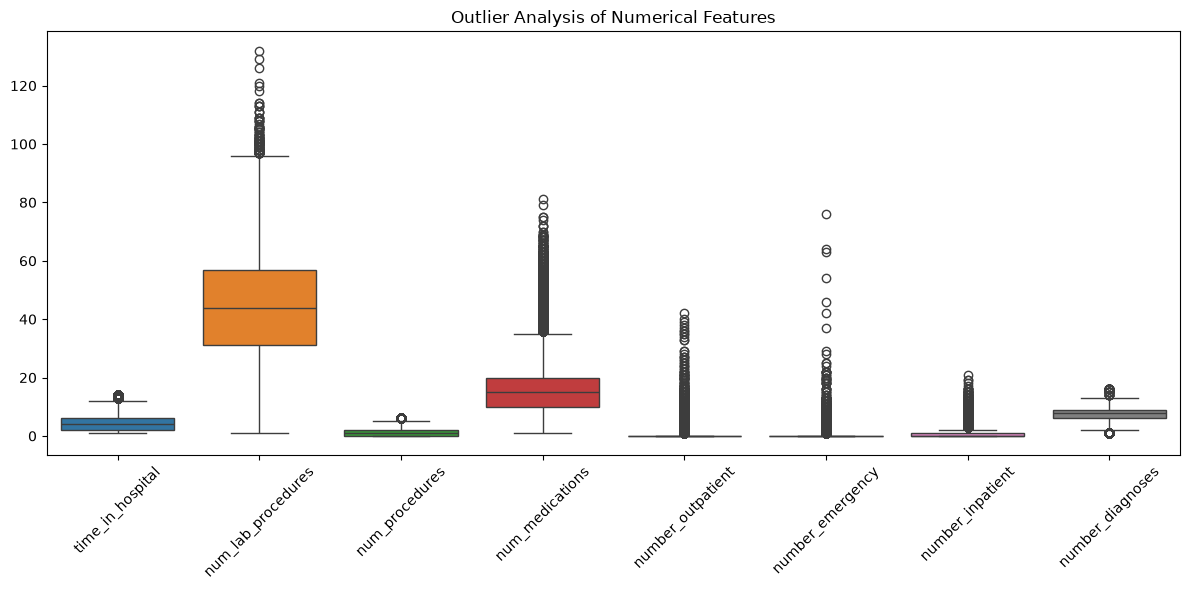

In [108]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[outlier_columns]
)

plt.title("Outlier Analysis of Numerical Features")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Outlier conclusion**

### Outlier Analysis Summary

The IQR method identified potential outliers in some numerical variables. However, I did not remove these values automatically because extreme values in healthcare data may represent real patient situations. The outlier analysis will be considered during model development.

## CORRELATION ANALYSIS

**Create correlation matrix**

In [109]:
# Correlation tells us how strongly two numerical variables move together.

correlation = df[outlier_columns + [
    "readmitted_30_days"
]].corr()

correlation

# -1 → Strong negative relationship
#  0 → Little/no linear relationship
# +1 → Strong positive relationship

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted_30_days
time_in_hospital,1.000000,0.318450,0.191472,0.466135,-0.008916,-0.009681,0.073623,0.220186,0.044199
num_lab_procedures,0.318450,1.000000,0.058066,0.268161,-0.007602,-0.002279,0.039231,0.152773,0.020364
num_procedures,0.191472,0.058066,1.000000,0.385767,-0.024819,-0.038179,-0.066236,0.073734,-0.012227
num_medications,0.466135,0.268161,0.385767,1.000000,0.045197,0.013180,0.064194,0.261526,0.038432
number_outpatient,-0.008916,-0.007602,-0.024819,0.045197,1.000000,0.091459,0.107338,0.094152,0.018893
number_emergency,-0.009681,-0.002279,-0.038179,0.013180,0.091459,1.000000,0.266559,0.055539,0.060747
number_inpatient,0.073623,0.039231,-0.066236,0.064194,0.107338,0.266559,1.000000,0.104710,0.165147
number_diagnoses,0.220186,0.152773,0.073734,0.261526,0.094152,0.055539,0.104710,1.000000,0.049524
readmitted_30_days,0.044199,0.020364,-0.012227,0.038432,0.018893,0.060747,0.165147,0.049524,1.000000


**Create correlation heatmap**

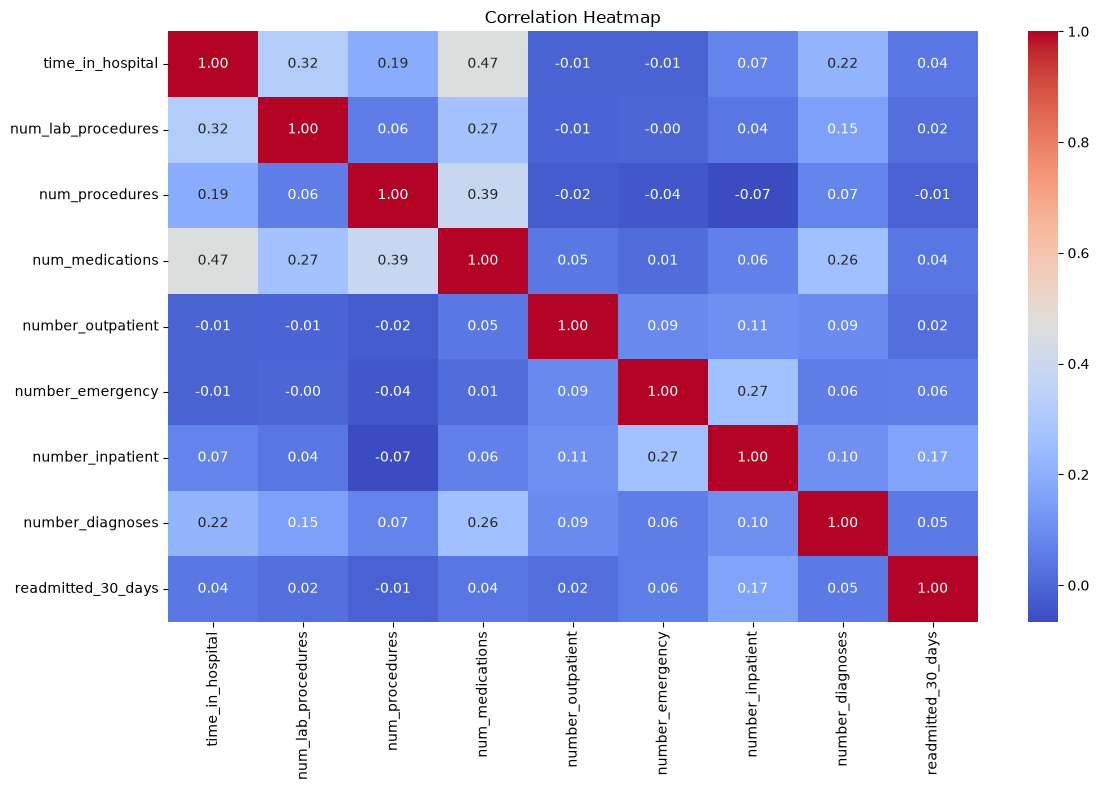

In [110]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

###I created a correlation heatmap to understand relationships between numerical variables and see which variables may have stronger relationships with the 30-day readmission target.###

**Check correlation with our target**

In [111]:
target_correlation = (
    correlation["readmitted_30_days"]
    .sort_values(ascending=False)
)

target_correlation

# I also checked the correlation of numerical features with the target variable. This helped me understand 
# which numerical variables have stronger or weaker linear relationships with 30-day readmission.

readmitted_30_days    1.000000
number_inpatient      0.165147
number_emergency      0.060747
number_diagnoses      0.049524
time_in_hospital      0.044199
num_medications       0.038432
num_lab_procedures    0.020364
number_outpatient     0.018893
num_procedures       -0.012227
Name: readmitted_30_days, dtype: float64

**Correlation summary**

### Correlation Analysis Summary

The correlation analysis helped me understand relationships between numerical variables. I also compared the numerical features with the 30-day readmission target. Correlation was used for understanding the data, not as the only method for selecting features.

## FEATURE ENGINEERING

**Create total previous visits**

In [112]:
df["total_previous_visits"] = (
    df["number_outpatient"]
    + df["number_emergency"]
    + df["number_inpatient"]
)

In [113]:
# Check the result
df[
    [
        "number_outpatient",
        "number_emergency",
        "number_inpatient",
        "total_previous_visits"
    ]
].head()


,number_outpatient,number_emergency,number_inpatient,total_previous_visits
0,0,0,0,0
1,0,0,0,0
2,2,0,1,3
3,0,0,0,0
4,0,0,0,0


###I created total_previous_visits by combining outpatient, emergency, and inpatient visits to represent overall previous healthcare utilization.###

**Create total procedures**

In [114]:
df["total_procedures"] = (
    df["num_lab_procedures"]
    + df["num_procedures"]
)

df[
    [
        "num_lab_procedures",
        "num_procedures",
        "total_procedures"
    ]
].head()

,num_lab_procedures,num_procedures,total_procedures
0,41,0,41
1,59,0,59
2,11,5,16
3,44,1,45
4,51,0,51


**Check our new features**

In [115]:
df[
    [
        "total_previous_visits",
        "total_procedures"
    ]
].describe()

,total_previous_visits,total_procedures
count,101766.000000,101766.000000
mean,1.202759,44.435371
std,2.291781,19.846605
min,0.000000,1.000000
25%,0.000000,33.000000
50%,0.000000,45.000000
75%,2.000000,58.000000
max,80.000000,135.000000


**Create X and y**

In [116]:
# Now we separate our features from our target.
# First, select the features:
selected_features = [
    "race",
    "gender",
    "age",
    "admission_type_id",
    "admission_source_id",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "max_glu_serum",
    "A1Cresult",
    "change",
    "diabetesMed",
    "total_previous_visits",
    "total_procedures"
]

X = df[selected_features].copy()

y = df["readmitted_30_days"].copy()

X = Information we give to the model
y = Answer we want the model to predict

**Check X and y**

In [117]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (101766, 19)
Target shape: (101766,)


In [118]:
X.head()

,race,gender,age,admission_type_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,max_glu_serum,A1Cresult,change,diabetesMed,total_previous_visits,total_procedures
0,Caucasian,Female,[0-10),6,1,1,41,0,1,0,0,0,1,NaN,NaN,No,No,0,41
1,Caucasian,Female,[10-20),1,7,3,59,0,18,0,0,0,9,NaN,NaN,Ch,Yes,0,59
2,AfricanAmerican,Female,[20-30),1,7,2,11,5,13,2,0,1,6,NaN,NaN,No,Yes,3,16
3,Caucasian,Male,[30-40),1,7,2,44,1,16,0,0,0,7,NaN,NaN,Ch,Yes,0,45
4,Caucasian,Male,[40-50),1,7,1,51,0,8,0,0,0,5,NaN,NaN,Ch,Yes,0,51


In [119]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: readmitted_30_days, dtype: int64

**Separate numerical and categorical features**

In [120]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

# I separated numerical and categorical features because they require different preprocessing before being used 
# by the machine learning model.

Numerical features:
['admission_type_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'total_previous_visits', 'total_procedures']

Categorical features:
['race', 'gender', 'age', 'max_glu_serum', 'A1Cresult', 'change', 'diabetesMed']


**Check missing values**

In [121]:
missing_features = X.isnull().sum()

missing_features = missing_features[
    missing_features > 0
].sort_values(ascending=False)

missing_features

max_glu_serum    96420
A1Cresult        84748
race              2273
dtype: int64

**Check target balance**

In [122]:
print(
    y.value_counts()
)

readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64


In [123]:
# Print the percentage
print(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

readmitted_30_days
0    88.84
1    11.16
Name: proportion, dtype: float64


**Check the final feature list**

In [124]:
print("Number of features:", len(X.columns))

print("\nSelected features:")

for feature in X.columns:
    print("-", feature)

Number of features: 19

Selected features:
- race
- gender
- age
- admission_type_id
- admission_source_id
- time_in_hospital
- num_lab_procedures
- num_procedures
- num_medications
- number_outpatient
- number_emergency
- number_inpatient
- number_diagnoses
- max_glu_serum
- A1Cresult
- change
- diabetesMed
- total_previous_visits
- total_procedures


**Keep patient ID for later splitting**

In [125]:
# One patient can have multiple hospital encounters.
# We don't want the same patient appearing in both training and testing data.
# So let's keep the patient ID separately.

patient_groups = df["patient_nbr"].copy()

print("Unique patients:", patient_groups.nunique())
print("Total encounters:", len(patient_groups))

Unique patients: 71518
Total encounters: 101766


**Save the model-ready data**

In [126]:
# Create the processed folder
from pathlib import Path

processed_folder = Path("../data/processed")

processed_folder.mkdir(
    parents=True,
    exist_ok=True
)

In [127]:
# Save the data
model_data = X.copy()

model_data["readmitted_30_days"] = y

# Keep patient ID only for grouping later.
# It will NOT be used as a model feature.
model_data["patient_nbr"] = patient_groups

model_data.to_csv(
    processed_folder / "model_ready_data.csv",
    index=False
)

print("Model-ready dataset saved successfully!")

Model-ready dataset saved successfully!


**Final check**

In [128]:
print("Final feature shape:", X.shape)

print(
    "\nTarget distribution:"
)

print(
    y.value_counts()
)

print(
    "\nPatient groups:",
    patient_groups.nunique()
)

print("\nCompleted successfully!")

Final feature shape: (101766, 19)

Target distribution:
readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64

Patient groups: 71518

Completed successfully!


## Conclusion

In this notebook, I prepared the dataset for machine learning.

Key steps completed:

- Analyzed potential outliers in important numerical variables using the IQR method.
- Visualized numerical variables using boxplots.
- Performed correlation analysis using a correlation matrix and heatmap.
- Reviewed the relationship between numerical features and the 30-day readmission target.
- Created `total_previous_visits` to represent overall previous healthcare utilization.
- Created `total_procedures` to combine laboratory and other procedures.
- Selected relevant numerical and categorical features.
- Separated the features (X) from the target (y).
- Checked missing values and target class balance.
- Kept the patient ID separately for patient-level train-test splitting.
- Saved the model-ready dataset.

The data is now prepared for the machine learning stage.

In the next notebook, I will preprocess the numerical and categorical features, split the data into training and testing sets, and train machine learning models to predict 30-day hospital readmission.